# Observatorio inmobiliario de Medellín: análisis exploratorio

Este notebook responde las ocho preguntas del proyecto con las **tablas agregadas** de `data/agregados/`, las mismas que se publican en el repositorio. No lee anuncios individuales, así que cualquiera que clone el repo puede volver a correrlo:

```bash
uv sync --group analisis
uv run --group analisis jupyter nbconvert --to notebook --execute --inplace notebooks/01_analisis_exploratorio.ipynb
```

**Advertencias antes de leer:**
- Los datos son una foto de 9 inmobiliarias de Medellín, no de todo el mercado.
- Son precios **publicados**, no precios de cierre.
- Solo se analizan anuncios de Medellín que no son atípicos, y los precios solo de vivienda (apartamento, apartaestudio y casa).
- Un precio se publica solo si resume 5 anuncios o más.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from observatorio_inmobiliario.almacenamiento import TABLAS_AGREGADAS, leer_agregado

%matplotlib inline
plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (9, 4.5), "axes.grid": True})
pd.options.display.float_format = "{:,.1f}".format

AGREGADOS = Path("../data/agregados")
t = {nombre: leer_agregado(AGREGADOS, nombre) for nombre in TABLAS_AGREGADAS}
semana = t["cobertura_inmobiliaria"]["semana"].iloc[0]
print(f"Semana analizada: {semana}")
pd.Series({nombre: len(tabla) for nombre, tabla in t.items()}, name="filas").to_frame()

Semana analizada: 2026-S46


,filas
precios_zona,494
cobertura_inmobiliaria,26
cobertura_comuna,387
economia_inmobiliaria,61
estratos_inmobiliaria,86
compartidos_fuentes,58
grupos_compartidos,694
evolucion_precios,8
rotacion_inmobiliaria,17


## 1. Precio por barrio

¿Cuánto cuesta el m² de vivienda en cada barrio? Se usa la **mediana**, que no se mueve por un par de anuncios extremos. Primero, los barrios más caros y más baratos en venta.

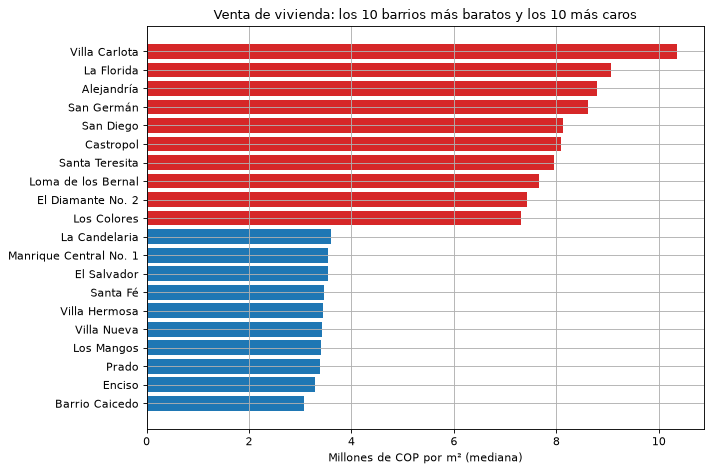

El barrio más caro cuesta 3.4 veces más por m² que el más barato.


In [2]:
pz = t["precios_zona"]
venta_barrio = pz.query("nivel == 'barrio' and operacion == 'venta' and tipo == 'vivienda'")
# Algunos barrios publican el precio total pero no el del m² (menos de 5 con área).
orden = venta_barrio.dropna(subset=["precio_m2_mediana"]).sort_values("precio_m2_mediana")
extremos = pd.concat([orden.head(10), orden.tail(10)])

fig, ax = plt.subplots(figsize=(9, 6))
colores = ["tab:blue"] * 10 + ["tab:red"] * 10
ax.barh(extremos["nombre"], extremos["precio_m2_mediana"] / 1e6, color=colores)
ax.set_xlabel("Millones de COP por m² (mediana)")
ax.set_title("Venta de vivienda: los 10 barrios más baratos y los 10 más caros")
plt.tight_layout()
plt.show()

ratio = orden["precio_m2_mediana"].iloc[-1] / orden["precio_m2_mediana"].iloc[0]
print(f"El barrio más caro cuesta {ratio:.1f} veces más por m² que el más barato.")

Por comuna se puede comparar venta y arriendo. La **rentabilidad bruta** es el arriendo de un año dividido por el precio de venta del m². Es una aproximación: compara medianas de anuncios distintos y no descuenta administración, impuestos ni vacancia.

In [3]:
comunas = pz.query("nivel == 'comuna' and tipo == 'vivienda'")
por_comuna = comunas.pivot_table(index="nombre", columns="operacion", values="precio_m2_mediana")
por_comuna = por_comuna.dropna()
por_comuna["rentabilidad_bruta_pct"] = por_comuna["arriendo"] * 12 / por_comuna["venta"] * 100
por_comuna.sort_values("venta", ascending=False)

operacion,arriendo,venta,rentabilidad_bruta_pct
nombre,,,
EL POBLADO,"55,172.0","8,689,762.0",7.6
ALTAVISTA,"28,182.0","7,071,429.0",4.8
LAURELES,"42,697.0","6,045,245.0",8.5
BELEN,"39,553.0","5,609,049.0",8.5
LA AMERICA,"40,000.0","5,500,000.0",8.7
ROBLEDO,"35,556.0","4,750,000.0",9.0
SAN CRISTOBAL,"35,357.0","4,500,988.0",9.4
LA CANDELARIA,"34,713.0","4,329,897.0",9.6
SAN ANTONIO DE PRADO,"31,981.0","4,285,714.0",9.0


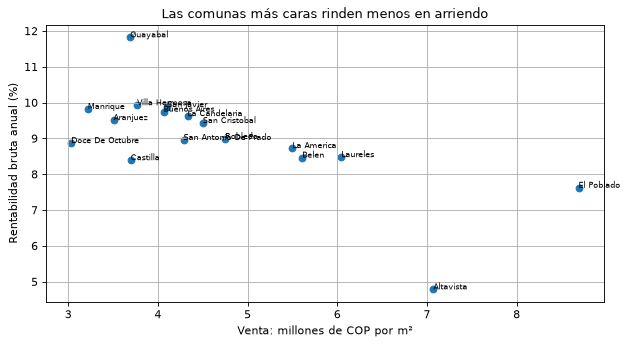

In [4]:
fig, ax = plt.subplots()
ax.scatter(por_comuna["venta"] / 1e6, por_comuna["rentabilidad_bruta_pct"])
for nombre, fila in por_comuna.iterrows():
    ax.annotate(nombre.title(), (fila["venta"] / 1e6, fila["rentabilidad_bruta_pct"]), fontsize=7)
ax.set_xlabel("Venta: millones de COP por m²")
ax.set_ylabel("Rentabilidad bruta anual (%)")
ax.set_title("Las comunas más caras rinden menos en arriendo")
plt.show()

## 2. Cobertura: ¿quién está en más barrios?

Cuántos barrios oficiales y comunas cubre cada inmobiliaria, y qué porcentaje de sus anuncios cae en su comuna principal. Un porcentaje alto indica una inmobiliaria especializada en una zona.

In [5]:
cobertura = t["cobertura_inmobiliaria"].query("operacion == 'todas'")
cobertura = cobertura.sort_values("barrios", ascending=False).set_index("fuente")
cobertura[["anuncios", "barrios", "comunas", "comuna_principal", "pct_comuna_principal"]]

,anuncios,barrios,comunas,comuna_principal,pct_comuna_principal
fuente,,,,,
nutibara,713,183,20,10,31.1
alnago,1235,179,21,10,23.0
villacruz,586,157,20,11,24.1
uribienes,372,120,19,14,28.8
maxibienes,1305,84,16,11,19.2
panorama,876,78,18,16,23.6
puertabierta,217,40,10,14,78.3
santafe,40,19,9,12,30.0
activourbano,286,10,6,14,88.1


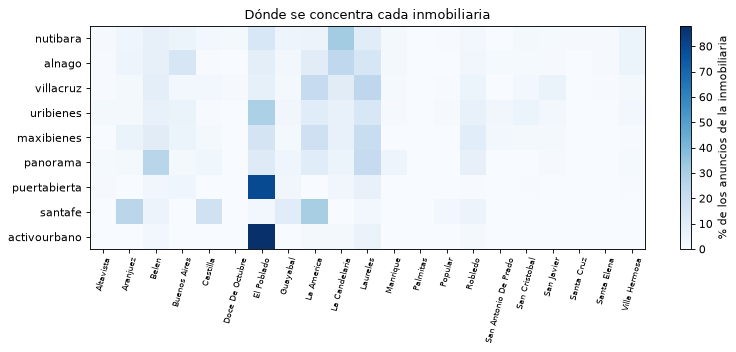

In [6]:
cc = t["cobertura_comuna"].query("operacion == 'todas'")
mapa = cc.pivot_table(
    index="fuente", columns="nombre_comuna", values="pct_de_la_fuente", fill_value=0
)
mapa = mapa.loc[cobertura.index]
fig, ax = plt.subplots(figsize=(10, 4.5))
imagen = ax.imshow(mapa, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(mapa.columns)), [c.title() for c in mapa.columns], rotation=75, fontsize=7)
ax.set_yticks(range(len(mapa.index)), mapa.index)
ax.grid(False)
fig.colorbar(imagen, label="% de los anuncios de la inmobiliaria")
ax.set_title("Dónde se concentra cada inmobiliaria")
plt.tight_layout()
plt.show()

## 3. Economía: ¿quién maneja lo más económico?

Comparar medianas de precio entre inmobiliarias engaña: una que trabaja en El Poblado siempre parece cara. Por eso se usa el **índice de precio relativo**: cada anuncio se divide por la mediana de su barrio (misma operación y tipo). Un índice de 0,95 es un 5 % por debajo de su barrio. Venta y arriendo van por separado.

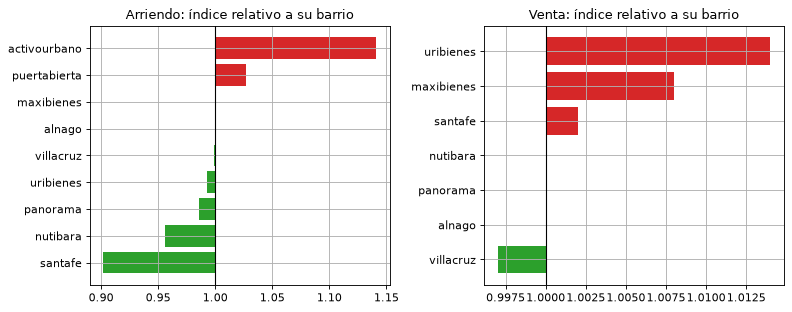

,fuente,operacion,anuncios,precio_mediana,precio_m2_mediana,anuncios_indice,indice_relativo_mediana
3,activourbano,arriendo,240,4500000,58333,16,1.1
5,activourbano,venta,39,690000000,9500000,3,NaN
9,alnago,arriendo,562,2700000,40000,359,1.0
13,alnago,venta,357,385000000,4270833,173,1.0
17,maxibienes,arriendo,641,3000000,42500,325,1.0
21,maxibienes,venta,323,508400000,5555556,137,1.0
25,nutibara,arriendo,243,2000000,29241,123,1.0
28,nutibara,venta,182,670000000,5000000,94,1.0
32,panorama,arriendo,431,2800000,37889,212,1.0
36,panorama,venta,231,450000000,5000000,68,1.0


In [7]:
eco = t["economia_inmobiliaria"].query("tipo == 'vivienda'")
indice = eco.pivot_table(index="fuente", columns="operacion", values="indice_relativo_mediana")
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=False)
for ax, operacion in zip(axes, ["arriendo", "venta"], strict=True):
    serie = indice[operacion].dropna().sort_values()
    colores = ["tab:green" if v < 1 else "tab:red" for v in serie]
    ax.barh(serie.index, serie - 1, left=1, color=colores)
    ax.axvline(1, color="black", linewidth=1)
    ax.set_title(f"{operacion.title()}: índice relativo a su barrio")
plt.tight_layout()
plt.show()
eco[
    [
        "fuente",
        "operacion",
        "anuncios",
        "precio_mediana",
        "precio_m2_mediana",
        "anuncios_indice",
        "indice_relativo_mediana",
    ]
]

## 4. Estratos: ¿quién trabaja estratos bajos y quién altos?

Se agrupan los estratos 1-3 (bajos) y 4-6 (altos). Alnago y Puertabierta no publican estrato. Para ellas se usa el **estrato inferido** del barrio, que acierta en el 76 % de los anuncios donde se puede comprobar. Por eso la parte inferida va en color claro.

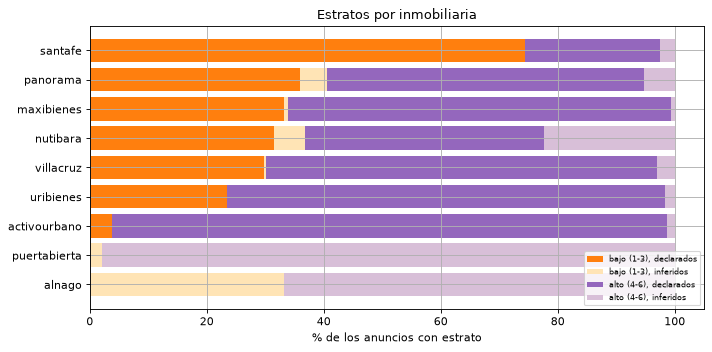

In [8]:
est = t["estratos_inmobiliaria"]
est = est.assign(grupo=est["estrato"].map(lambda e: "bajo (1-3)" if e <= 3 else "alto (4-6)"))
resumen = est.groupby(["fuente", "grupo"])[["declarados", "inferidos"]].sum().unstack(fill_value=0)
total = resumen.sum(axis=1)
pct = resumen.div(total, axis=0) * 100
pct = pct.sort_values(("declarados", "bajo (1-3)"))

fig, ax = plt.subplots()
izquierda = pd.Series(0.0, index=pct.index)
for (origen, grupo), color in {
    ("declarados", "bajo (1-3)"): "tab:orange",
    ("inferidos", "bajo (1-3)"): "moccasin",
    ("declarados", "alto (4-6)"): "tab:purple",
    ("inferidos", "alto (4-6)"): "thistle",
}.items():
    valores = pct.get((origen, grupo), pd.Series(0.0, index=pct.index))
    ax.barh(pct.index, valores, left=izquierda, color=color, label=f"{grupo}, {origen}")
    izquierda += valores
ax.set_xlabel("% de los anuncios con estrato")
ax.legend(fontsize=7, loc="lower right")
ax.set_title("Estratos por inmobiliaria")
plt.tight_layout()
plt.show()

## 5. Reputación y 6. Reconocimiento

**Reputación (pregunta 5):** se mide con la calificación y el número de reseñas de la API oficial de Google Places. Sus términos no permiten guardarlas, así que se consultan en vivo desde el dashboard y no aparecen en este notebook.

**Reconocimiento (pregunta 6):** es un indicador propio que combina volumen de anuncios, barrios cubiertos y número de reseñas. Aquí están los dos primeros componentes; las reseñas se suman en el dashboard.

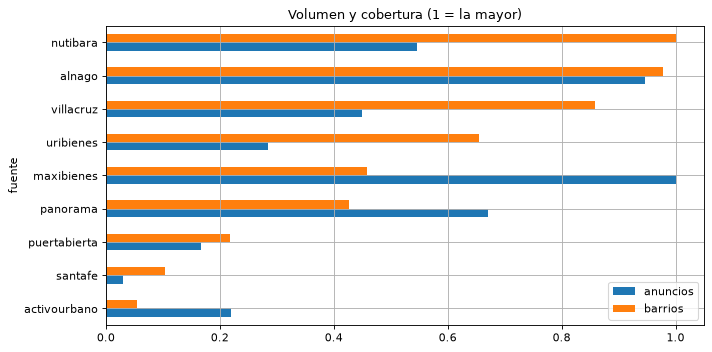

In [9]:
componentes = cobertura[["anuncios", "barrios"]].astype(float)
normalizado = componentes / componentes.max()
normalizado.sort_values("barrios").plot.barh(title="Volumen y cobertura (1 = la mayor)")
plt.tight_layout()
plt.show()

## 7. Propiedades compartidas

El mismo inmueble publicado por dos inmobiliarias distintas. Cada pareja tiene una confianza: **alta** (a 100 m o menos, con las mismas características), **media** o **baja**. Los niveles son acumulados: "media" incluye las parejas alta y media.

La tabla publicada tiene la diferencia de precio mediana **de cada par de inmobiliarias**. Por eso el resumen por nivel muestra la mediana de esas medianas, que no es exactamente la mediana de todas las parejas.

In [10]:
cf = t["compartidos_fuentes"]
cf.groupby("nivel", sort=False).agg(
    parejas=("parejas", "sum"),
    mediana_de_medianas_por_par_pct=("diferencia_precio_mediana_pct", "median"),
)

,parejas,mediana_de_medianas_por_par_pct
nivel,,
alta,53,2.1
media,136,5.3
baja,230,7.9


In [11]:
media = cf.query("nivel == 'media'").sort_values("parejas", ascending=False).head(8)
media = media.assign(par=media["fuente_a"] + " – " + media["fuente_b"])
media.set_index("par")[
    ["parejas", "diferencia_precio_mediana_pct", "pct_a_mas_barata", "pct_mismo_precio"]
]

,parejas,diferencia_precio_mediana_pct,pct_a_mas_barata,pct_mismo_precio
par,,,,
nutibara – villacruz,27,0.0,14.8,66.7
alnago – villacruz,18,4.8,33.3,33.3
uribienes – villacruz,16,6.8,37.5,12.5
alnago – uribienes,12,10.0,41.7,16.7
alnago – nutibara,11,6.9,45.5,18.2
maxibienes – panorama,10,4.3,10.0,20.0
panorama – villacruz,9,15.0,55.6,11.1
maxibienes – villacruz,7,3.7,42.9,14.3


## 8. Evolución en el tiempo

Con el histórico semanal se mide cuánto dura publicado un inmueble, cuánto cambian los precios y quién rota inventario más rápido (tasa de retiro semanal). Cada semana se compara con la anterior que tiene datos.

In [12]:
evolucion, rotacion = t["evolucion_precios"], t["rotacion_inmobiliaria"]
semanas = sorted(evolucion["semana"].unique())
print(f"Semanas con datos: {len(semanas)} ({', '.join(semanas)})")
rotacion.groupby("semana")[["anuncios", "retirados", "comparables", "con_cambio_precio"]].sum()

Semanas con datos: 1 (2026-S46)


,anuncios,retirados,comparables,con_cambio_precio
semana,,,,
2026-S46,5696,0,0,0


Por ahora hay **una sola semana**: todavía no hay retiros ni cambios de precio que medir. Las tablas ya están listas y se llenan solas con la ejecución semanal automática.

## Hallazgos

Cifras de la semana 2026-S46, sobre anuncios de vivienda de Medellín:

1. **El m² de vivienda en venta más caro de Medellín cuesta 3,4 veces el más barato:** Villa Carlota (El Poblado) tiene una mediana de 10,4 millones por m², y Barrio Caicedo (comuna 9), 3,1 millones.
2. **Las comunas más caras rinden menos en arriendo.** La rentabilidad bruta anual es 7,6 % en El Poblado y llega a 9,9 % en Villa Hermosa y San Javier (11,8 % en Guayabal).
3. **Nutibara y Alnago son las de mayor cobertura** (183 y 179 barrios). Activo Urbano y Puertabierta son especialistas: el 88 % y el 78 % de sus anuncios están en El Poblado.
4. **Frente a su propio barrio, la mayoría cobra casi lo mismo** (índice entre 0,99 y 1,03). Activo Urbano en arriendo queda un 14 % por encima, y Nutibara un 4 % por debajo (Santa Fe, un 10 % por debajo, pero con solo 5 anuncios comparables).
5. **Nutibara y Panorama son las que más trabajan estratos 1 a 3** según el estrato que declaran (44 % y 40 %; Santa Fe llega al 76 %, pero con solo 38 anuncios). Activo Urbano casi no tiene (4 %). Alnago y Puertabierta no publican estrato: con el inferido de su barrio, Puertabierta queda en 2 %.
6. **Hay 53 parejas de alta confianza entre inmobiliarias, con una diferencia de precio mediana de solo 2 %.** Nutibara y Villacruz publican el mismo precio exacto en dos de cada tres inmuebles que comparten, lo que encaja con inventario compartido por MLS.

**Limitaciones:**
- Una sola semana de datos: la pregunta 8 todavía no tiene resultados.
- Maxibienes, Panorama y Activo Urbano no publican coordenadas, así que su barrio depende del nombre que escriben y sus parejas compartidas nunca pasan de confianza media.
- El estrato inferido acierta en el 76 % de los casos comprobables.
- La rentabilidad bruta compara medianas de anuncios distintos: es una orientación, no un cálculo de inversión.